Język: [English](examples.en.ipynb) | **Polski**

# Wykład 04 — eksperyment: geometria optymalizacji i trening MLP

Materiał towarzyszący [`lecture.md`](lecture.md). Dwa eksperymenty: (1)
zachowanie SGD/momentum/Adam na dwuwymiarowej, źle uwarunkowanej misce
kwadratowej — poziomice, trajektorie, granice stabilności; (2) trening
małego MLP na danych syntetycznych, porównanie przy wspólnym i osobno
dobranym learning rate.


In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")


Używane urządzenie: cpu


## 1. Geometria optymalizacji

$f(x,y) = \tfrac12(a x^2 + b y^2)$, $a=25$, $b=1$ — stromo w $x$, płasko w
$y$. Minimum w $(0,0)$, start w $(1,1)$.


In [2]:
A, B = 25.0, 1.0
START = [1.0, 1.0]


def f(xy):
    return 0.5 * (A * xy[0] ** 2 + B * xy[1] ** 2)


def run(opt_name, lr, steps, momentum=0.9, betas=(0.9, 0.999)):
    theta = torch.tensor(START, requires_grad=True)
    if opt_name == "sgd":
        opt = torch.optim.SGD([theta], lr=lr)
    elif opt_name == "momentum":
        opt = torch.optim.SGD([theta], lr=lr, momentum=momentum)
    elif opt_name == "adam":
        opt = torch.optim.Adam([theta], lr=lr, betas=betas)
    traj = [theta.detach().clone().tolist()]
    losses = [f(theta).item()]
    for _ in range(steps):
        opt.zero_grad()
        loss = f(theta)
        loss.backward()
        opt.step()
        traj.append(theta.detach().clone().tolist())
        losses.append(f(theta).item())
    return traj, losses


def plot_contours(ax, xlim=(-1.3, 1.3), ylim=(-1.3, 1.3)):
    xs = torch.linspace(*xlim, 200)
    ys = torch.linspace(*ylim, 200)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    ZZ = 0.5 * (A * XX**2 + B * YY**2)
    ax.contour(XX, YY, ZZ, levels=20, cmap="Greys", alpha=0.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")


def plot_trajectory(ax, traj, label, **kwargs):
    xs = [p[0] for p in traj]
    ys = [p[1] for p in traj]
    ax.plot(xs, ys, marker="o", markersize=3, linewidth=1, label=label, **kwargs)


### SGD: granica stabilności

Teoria: dla $f=\tfrac12 a x^2$ zwykły spadek gradientu jest stabilny dla
$\eta < 2/a$. Tu $a=25$, więc granica to $\eta=0{,}08$.


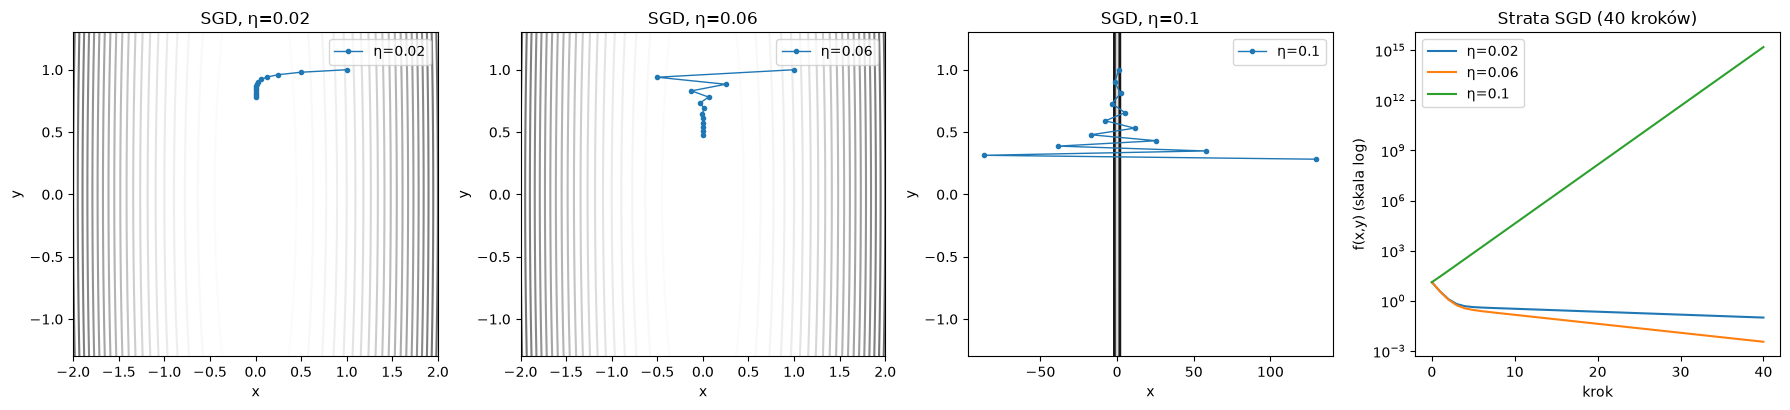

SGD eta=0.02: strata koncowa=0.0993  zmiany znaku x=0  ostatni x=0.000
SGD eta=0.06: strata koncowa=0.0035  zmiany znaku x=40  ostatni x=0.000
SGD eta=0.1: strata koncowa=1528309217230848.0000  zmiany znaku x=40  ostatni x=11057339.000


In [3]:
lrs_sgd = [0.02, 0.06, 0.1]
results_sgd = {lr: run("sgd", lr, steps=40) for lr in lrs_sgd}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, lr in zip(axes[:3], lrs_sgd):
    traj, _ = results_sgd[lr]
    traj_short = traj[:13]  # jakosciowe zachowanie widac juz w pierwszych krokach
    plot_contours(ax, xlim=(-2, 2), ylim=(-1.3, 1.3))
    plot_trajectory(ax, traj_short, f"η={lr}")
    ax.set_title(f"SGD, η={lr}")
    ax.legend()

for lr in lrs_sgd:
    _, losses = results_sgd[lr]
    axes[3].semilogy([v + 1e-12 for v in losses], label=f"η={lr}")
axes[3].set_xlabel("krok")
axes[3].set_ylabel("f(x,y) (skala log)")
axes[3].set_title("Strata SGD (40 kroków)")
axes[3].legend()
plt.tight_layout()
plt.show()

for lr in lrs_sgd:
    traj, losses = results_sgd[lr]
    xs = [p[0] for p in traj]
    sign_changes = sum(1 for i in range(1, len(xs)) if xs[i] * xs[i - 1] < 0)
    print(f"SGD eta={lr}: strata koncowa={losses[-1]:.4f}  "
          f"zmiany znaku x={sign_changes}  ostatni x={xs[-1]:.3f}")


### Momentum: ten sam $\eta$ co oscylujący SGD, różne $\beta$

$\eta=0{,}06$ — dla zwykłego SGD oscyluje, ale zbiega (zobacz wyżej).


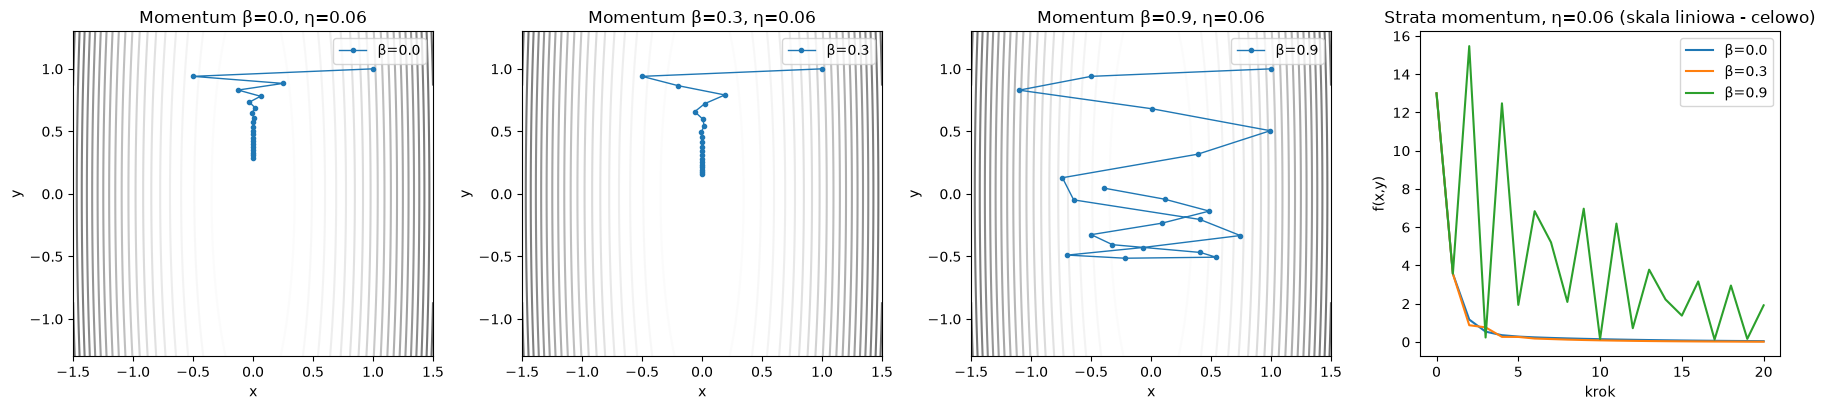

momentum beta=0.0: strata po 20 krokach=0.0421  min=0.0421 max=13.0000
momentum beta=0.3: strata po 20 krokach=0.0130  min=0.0130 max=13.0000
momentum beta=0.9: strata po 20 krokach=1.9163  min=0.1290 max=15.4691


In [4]:
lr_shared = 0.06
betas_to_try = [0.0, 0.3, 0.9]
results_mom = {beta: run("momentum", lr_shared, steps=20, momentum=beta) for beta in betas_to_try}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, beta in zip(axes[:3], betas_to_try):
    traj, _ = results_mom[beta]
    plot_contours(ax, xlim=(-1.5, 1.5), ylim=(-1.3, 1.3))
    plot_trajectory(ax, traj, f"β={beta}")
    ax.set_title(f"Momentum β={beta}, η={lr_shared}")
    ax.legend()

for beta in betas_to_try:
    _, losses = results_mom[beta]
    axes[3].plot(losses, label=f"β={beta}")
axes[3].set_xlabel("krok")
axes[3].set_ylabel("f(x,y)")
axes[3].set_title(f"Strata momentum, η={lr_shared} (skala liniowa - celowo)")
axes[3].legend()
plt.tight_layout()
plt.show()

for beta in betas_to_try:
    traj, losses = results_mom[beta]
    print(f"momentum beta={beta}: strata po 20 krokach={losses[-1]:.4f}  "
          f"min={min(losses):.4f} max={max(losses):.4f}")


$\beta=0{,}9$ przy tym samym $\eta=0{,}06$ nie zbiega (strata skacze, nie
maleje konsekwentnie) — potrzebuje mniejszego $\eta$:


In [5]:
traj_small_lr, losses_small_lr = run("momentum", 0.02, steps=40, momentum=0.9)
print(f"momentum beta=0.9, eta=0.02: strata po 40 krokach = {losses_small_lr[-1]:.6f}")
print("(dla porownania: beta=0.9 przy eta=0.06 po 20 krokach nie schodzi ponizej "
      f"{min(results_mom[0.9][1]):.4f})")


momentum beta=0.9, eta=0.02: strata po 40 krokach = 0.003000
(dla porownania: beta=0.9 przy eta=0.06 po 20 krokach nie schodzi ponizej 0.1290)


### Adam: skalowanie per-parametr

Mimo 25-krotnej różnicy krzywizny ($x$ vs. $y$), zobacz trajektorie.


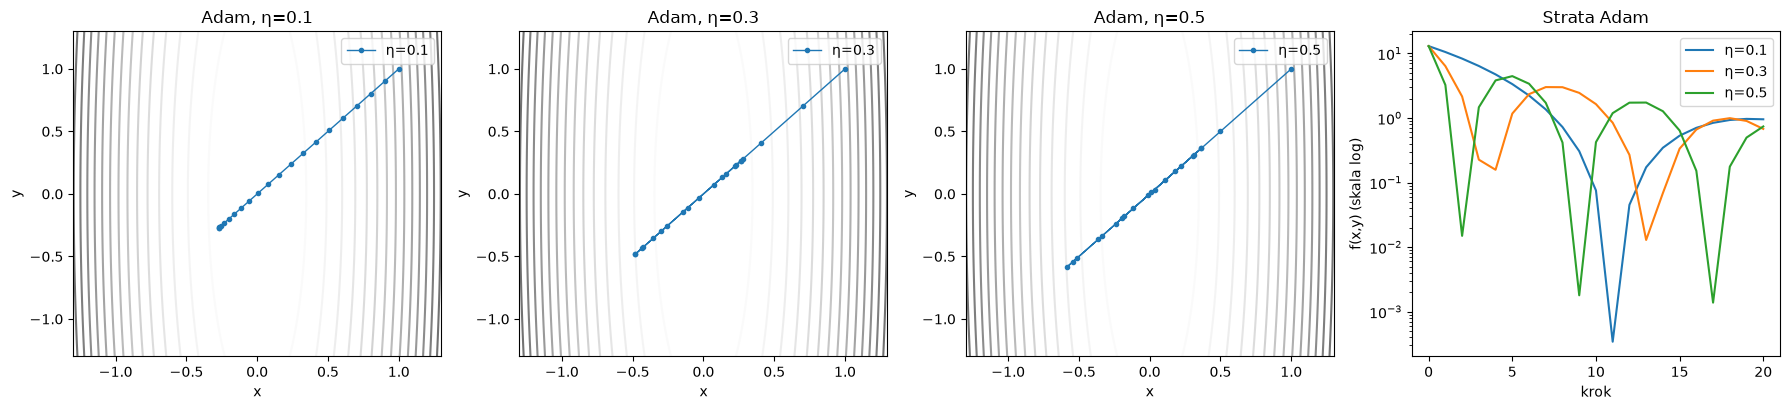

Adam eta=0.1: maksymalna |x-y| wzdluz calej trajektorii = 5.96e-08
(x i y sa praktycznie identyczne na kazdym kroku, mimo a/b=25 roznicy krzywizny)


In [6]:
lrs_adam = [0.1, 0.3, 0.5]
results_adam = {lr: run("adam", lr, steps=20) for lr in lrs_adam}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, lr in zip(axes[:3], lrs_adam):
    traj, _ = results_adam[lr]
    plot_contours(ax, xlim=(-1.3, 1.3), ylim=(-1.3, 1.3))
    plot_trajectory(ax, traj, f"η={lr}")
    ax.set_title(f"Adam, η={lr}")
    ax.legend()

for lr in lrs_adam:
    _, losses = results_adam[lr]
    axes[3].semilogy([v + 1e-12 for v in losses], label=f"η={lr}")
axes[3].set_xlabel("krok")
axes[3].set_ylabel("f(x,y) (skala log)")
axes[3].set_title("Strata Adam")
axes[3].legend()
plt.tight_layout()
plt.show()

traj01, _ = results_adam[0.1]
max_xy_diff = max(abs(p[0] - p[1]) for p in traj01)
print(f"Adam eta=0.1: maksymalna |x-y| wzdluz calej trajektorii = {max_xy_diff:.2e}")
print("(x i y sa praktycznie identyczne na kazdym kroku, mimo a/b=25 roznicy krzywizny)")


## 2. Trening MLP: wspólny kontra osobno dobrany learning rate

Dwa przeplatające się półksiężyce, $N=2\,000$, podział 80/20, mini-batche
po 64 przykłady (jawna funkcja losująca indeksy, z ustalonym ziarnem).


In [7]:
def make_moons(n_samples, noise, seed):
    g = torch.Generator().manual_seed(seed)
    n0 = n_samples // 2
    n1 = n_samples - n0
    theta0 = torch.pi * torch.rand(n0, generator=g)
    moon0 = torch.stack([torch.cos(theta0), torch.sin(theta0)], dim=1)
    theta1 = torch.pi * torch.rand(n1, generator=g)
    moon1 = torch.stack([1 - torch.cos(theta1), 1 - torch.sin(theta1) - 0.5], dim=1)
    X = torch.cat([moon0, moon1], dim=0)
    y = torch.cat([torch.zeros(n0), torch.ones(n1)])
    X = X + noise * torch.randn(X.shape[0], 2, generator=g)
    perm = torch.randperm(X.shape[0], generator=g)
    return X[perm], y[perm]


X, y = make_moons(n_samples=2000, noise=0.25, seed=0)
n = X.shape[0]
split_perm = torch.randperm(n, generator=torch.Generator().manual_seed(1))
n_val = int(0.2 * n)
val_idx, train_idx = split_perm[:n_val], split_perm[n_val:]
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
print(f"N_train={len(train_idx)}, N_val={len(val_idx)}")


def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 1))


def iterate_minibatches(X, y, batch_size, seed):
    """Jawne tworzenie mini-batchy: permutacja indeksow, pociecie na kawalki."""
    g = torch.Generator().manual_seed(seed)
    n = X.shape[0]
    perm = torch.randperm(n, generator=g)
    for i in range(0, n, batch_size):
        idx = perm[i : i + batch_size]
        yield X[idx], y[idx]


def train_model(opt_name, lr, epochs, batch_size=64, model_seed=42, data_seed=123, momentum=0.9):
    model = make_model(model_seed)
    if opt_name == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr)
    elif opt_name == "momentum":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    elif opt_name == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    train_losses, val_losses = [], []
    for epoch in range(epochs):
        for xb, yb in iterate_minibatches(X_train, y_train, batch_size, seed=data_seed + epoch):
            opt.zero_grad()
            logits = model(xb).squeeze(-1)
            loss = loss_fn(logits, yb)
            loss.backward()
            opt.step()
        with torch.no_grad():
            train_losses.append(loss_fn(model(X_train).squeeze(-1), y_train).item())
            val_losses.append(loss_fn(model(X_val).squeeze(-1), y_val).item())
    return train_losses, val_losses


N_train=1600, N_val=400


### Eksperyment kontrolowany: wspólny $\eta=0{,}01$ dla wszystkich trzech


sgd        (eta=0.01)  train@30=0.3295  val@30=0.3739
momentum   (eta=0.01)  train@30=0.2541  val@30=0.3023


adam       (eta=0.01)  train@30=0.1302  val@30=0.1503


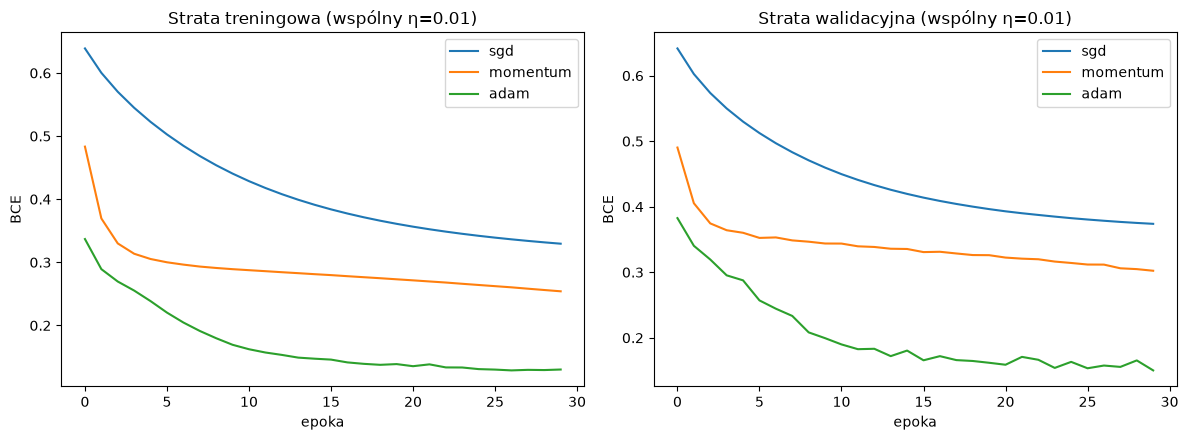

In [8]:
EPOCHS = 30
common_results = {}
for name in ["sgd", "momentum", "adam"]:
    tl, vl = train_model(name, lr=0.01, epochs=EPOCHS)
    common_results[name] = (tl, vl)
    print(f"{name:10s} (eta=0.01)  train@{EPOCHS}={tl[-1]:.4f}  val@{EPOCHS}={vl[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (tl, vl) in common_results.items():
    axes[0].plot(tl, label=name)
    axes[1].plot(vl, label=name)
axes[0].set_title("Strata treningowa (wspólny η=0.01)")
axes[1].set_title("Strata walidacyjna (wspólny η=0.01)")
for ax in axes:
    ax.set_xlabel("epoka")
    ax.set_ylabel("BCE")
    ax.legend()
plt.tight_layout()
plt.show()


### Eksperyment z osobno dobranym $\eta$ dla każdego algorytmu

**To jest inny eksperyment niż powyżej** — każdy optymalizator dostaje
$\eta$ dobrany dla niego osobno, nie wspólny.


sgd        (eta=0.5)  train@30=0.1379  val@30=0.1717


momentum   (eta=0.1)  train@30=0.1262  val@30=0.1520
adam       (eta=0.01)  train@30=0.1302  val@30=0.1503


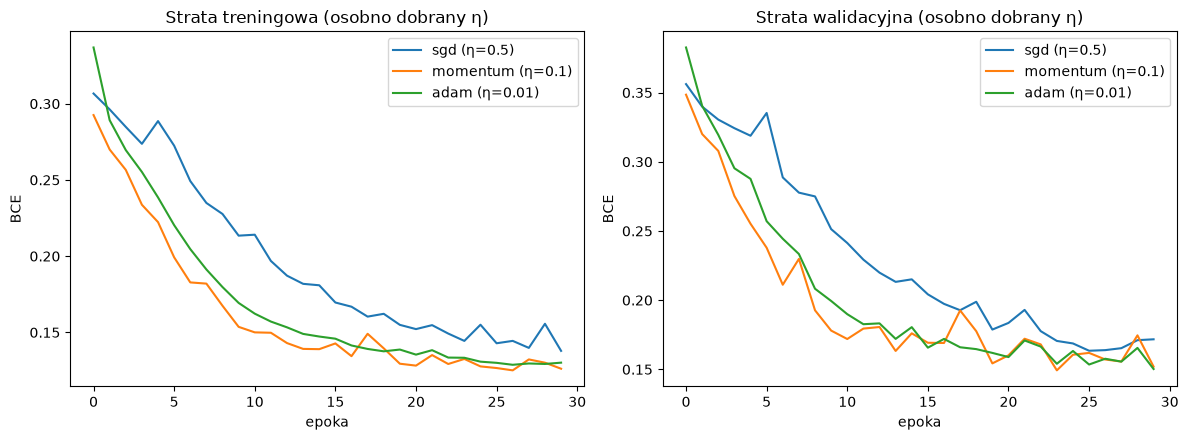

In [9]:
tuned_lrs = {"sgd": 0.5, "momentum": 0.1, "adam": 0.01}
tuned_results = {}
for name, lr in tuned_lrs.items():
    tl, vl = train_model(name, lr=lr, epochs=EPOCHS)
    tuned_results[name] = (tl, vl)
    print(f"{name:10s} (eta={lr})  train@{EPOCHS}={tl[-1]:.4f}  val@{EPOCHS}={vl[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (tl, vl) in tuned_results.items():
    axes[0].plot(tl, label=f"{name} (η={tuned_lrs[name]})")
    axes[1].plot(vl, label=f"{name} (η={tuned_lrs[name]})")
axes[0].set_title("Strata treningowa (osobno dobrany η)")
axes[1].set_title("Strata walidacyjna (osobno dobrany η)")
for ax in axes:
    ax.set_xlabel("epoka")
    ax.set_ylabel("BCE")
    ax.legend()
plt.tight_layout()
plt.show()


### Wpływ learning rate na stabilność (SGD)


SGD eta=1.0: strata treningowa po 15 epokach = 0.1456  (pierwsze 5: [0.291, 0.282, 0.269, 0.238, 0.285])
SGD eta=3.0: strata treningowa po 15 epokach = 0.1380  (pierwsze 5: [0.246, 0.21, 0.169, 0.145, 0.167])
SGD eta=8.0: strata treningowa po 15 epokach = 0.2750  (pierwsze 5: [0.297, 0.296, 0.322, 0.266, 0.705])
SGD eta=15.0: strata treningowa po 15 epokach = 1.6623  (pierwsze 5: [0.48, 0.532, 0.466, 0.992, 0.611])


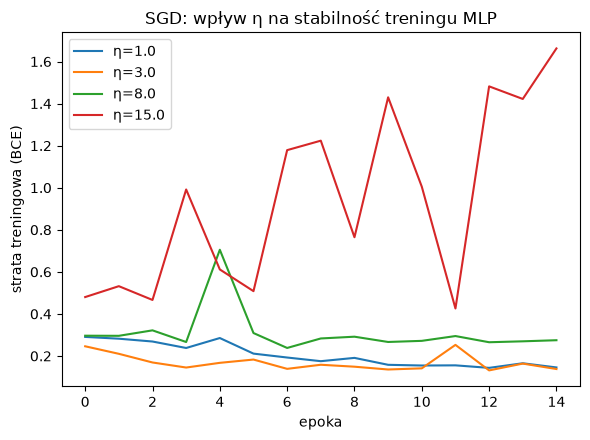

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for lr in [1.0, 3.0, 8.0, 15.0]:
    tl, _ = train_model("sgd", lr=lr, epochs=15)
    ax.plot(tl, label=f"η={lr}")
    first5 = [round(x, 3) for x in tl[:5]]
    print(f"SGD eta={lr}: strata treningowa po 15 epokach = {tl[-1]:.4f}  (pierwsze 5: {first5})")
ax.set_xlabel("epoka")
ax.set_ylabel("strata treningowa (BCE)")
ax.set_title("SGD: wpływ η na stabilność treningu MLP")
ax.legend()
plt.tight_layout()
plt.show()


## Podsumowanie

- Granica stabilności SGD na naszej misce jest dokładnie tam, gdzie
  przewiduje teoria ($\eta=2/a$); momentum przesuwa tę granicę, i to w obie
  strony — $\beta$ dobrze dobrane do $\eta$ pomaga, źle dobrane szkodzi.
- Adam normalizuje krok per-parametr — ten sam $\eta$ daje (na tej
  misce) identyczne zachowanie w kierunku stromym i płaskim.
- Porównanie przy wspólnym $\eta$ i porównanie przy osobno dobranym
  $\eta$ dały **różne** wnioski — to nie przypadek, to jest ten sam efekt,
  o którym mówi wykład: przewaga obserwowana przy jednym $\eta$ bywa
  przewagą w odporności na dobór $\eta$, nie w jakości samego mechanizmu.

Pytania do dyskusji i bibliografia: zobacz [`lecture.md`](lecture.md).
